In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc
import random
from sklearn.decomposition import NMF, non_negative_factorization

In [2]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])

tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [3]:
#reordering dataframe to match order of presence/absence matrix and DHS metadata dataframe
#first bigwig file
# GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF691MRD.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

#second bigwig file
GM06990_signal = pd.read_table('/home/ctrader/lightfm_data/out_ENCFF962FBP.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'mean'])

GM06990_signal[['name']] = GM06990_signal[['name']].astype(str)
GM06990_signal = GM06990_signal.set_index('name')
id_order = DHS_metadata['identifier'].to_list()
GM06990_signal = GM06990_signal.reindex(id_order)
GM06990_signal = GM06990_signal.reset_index()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

(733, 3591898)

In [5]:
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)

In [6]:
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)

In [7]:
decomp_Mixture.shape

(16, 3591898)

In [8]:
print(decomp_Basis.shape)
print(decomp_Mixture.shape)

(733, 16)
(16, 3591898)


In [9]:
dhs_array = dhs.to_numpy()

In [10]:
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

733 3591898


**Fill in DHS matrix (step by step)**

In [15]:
#Generate scores for each interaction
scores = np.dot(decomp_Basis, decomp_Mixture)
scores.shape

(733, 3591898)

In [16]:
#finding known positives for all biosamples
full_kp = np.where(dhs_array==1)

In [18]:
#sorting scores for each biosample
sorted_scores = np.argsort(-scores, axis=1)

In [19]:
cut_size = 1000

In [20]:
#for each row, updating DHS entries based on top predicted scores (ie top cut_size DHS indices=1)
updated_dhs_array = np.copy(dhs_array)
for biosample in range(n_biosamples):
    filtered_sorted_scores = np.delete(sorted_scores[biosample], np.where(np.isin(sorted_scores[biosample], full_kp[1][full_kp[0]==biosample])))
    first_cut_dhss = filtered_sorted_scores[:cut_size]
    updated_dhs_array[biosample, first_cut_dhss] = 1

In [21]:
new_dhs = pd.DataFrame(updated_dhs_array)
new_dhs.shape

(733, 3591898)

In [22]:
#regenerate NMF decompositions
new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=decomp_Basis, H=decomp_Mixture, n_components=16, init='custom', random_state=3, verbose=1)

violation: 1.0
violation: 0.23706175791380216
violation: 0.10904926264049893
violation: 0.07474534232668463
violation: 0.05767576980318156
violation: 0.04678546513014218
violation: 0.03912276188767488
violation: 0.033340644385284474
violation: 0.028944327572271954
violation: 0.02549123032288676
violation: 0.022675291932511554
violation: 0.020309176066792344
violation: 0.018243672939899355
violation: 0.0164433418957074
violation: 0.01484910420497907
violation: 0.013431502600385265
violation: 0.012167728922672132
violation: 0.011039648619792956
violation: 0.010026180059922594
violation: 0.009113118168858491
violation: 0.008288711806228952
violation: 0.007544586942751981
violation: 0.006873542026561206
violation: 0.00626775210366227
violation: 0.005720696832018984
violation: 0.005226874183676665
violation: 0.004780696698075769
violation: 0.004377243549527315
violation: 0.0040125738458316445
violation: 0.003682554472682657
violation: 0.003382627725825837
violation: 0.0031097043342019366
vi

**Using Fill in Function**

In [13]:
updated_dhs_array_1_cycle, new_decomp_Basis_1_cycle, new_decomp_Mixture_1_cycle = fill_in(cut_size=10000, cycles=1)

Starting Cycle 1 / 1
difference check: 7330000
NMF Decomposition:
violation: 1.0
violation: 0.22994449262030303
violation: 0.09795133939950146
violation: 0.06619030850214343
violation: 0.05047942813275997
violation: 0.039804322451766516
violation: 0.03210103711996027
violation: 0.026347708356290165
violation: 0.02184029069637115
violation: 0.018298405484414994
violation: 0.015406403545629771
violation: 0.01298326417539469
violation: 0.010992525452903436
violation: 0.00936567163266433
violation: 0.008018351839919183
violation: 0.006898775117827442
violation: 0.005966105027541934
violation: 0.005193458714132423
violation: 0.004538689673063253
violation: 0.003986330484607672
violation: 0.0035193769382953345
violation: 0.0031305237117573116
violation: 0.0028101852966990496
violation: 0.00254413876682222
violation: 0.002320648433059749
violation: 0.002130973899588771
violation: 0.001971627675589798
violation: 0.0018347952785097408
violation: 0.0017172035510155345
violation: 0.00161516527506

In [14]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_1_cycle_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(updated_dhs_array_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_1_cycle_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Basis_1_cycle, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_1_cycle_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Mixture_1_cycle, pickle_out)
pickle_out.close()

In [13]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_1_cycle_fill_10000_CT20211209.pickle', 'rb')
updated_dhs_array_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_1_cycle_fill_10000_CT20211209.pickle', 'rb')
new_decomp_Basis_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_1_cycle_fill_10000_CT20211209.pickle', 'rb')
new_decomp_Mixture_1_cycle=pickle.load(pickle_in)

In [14]:
updated_dhs_array_2_cycles, new_decomp_Basis_2_cycles, new_decomp_Mixture_2_cycles = fill_in(Basis=new_decomp_Basis_1_cycle, Mixture=new_decomp_Mixture_1_cycle, dhs_arr=updated_dhs_array_1_cycle, cut_size=10000, cycles=1)

Starting Cycle 1 / 1
difference check: 7330000
NMF Decomposition:
violation: 1.0
violation: 0.23616120232741442
violation: 0.09751479942170455
violation: 0.06056155815234619
violation: 0.043458745335063026
violation: 0.033123398464114565
violation: 0.026379168989746172
violation: 0.02154475017677024
violation: 0.01794426197206815
violation: 0.015271319613596759
violation: 0.01322367707035115
violation: 0.011679586846517029
violation: 0.010447131717450394
violation: 0.009454430685563382
violation: 0.008646141898800579
violation: 0.007991690655033603
violation: 0.0074504532402603985
violation: 0.006993558757159101
violation: 0.006604521061481325
violation: 0.006273887224141319
violation: 0.005993879884434597
violation: 0.005753731393447172
violation: 0.005545461100306815
violation: 0.005361509591134853
violation: 0.005195791166990095
violation: 0.005043674277075612
violation: 0.0049007555553357545
violation: 0.004764437412099799
violation: 0.004632629888311781
violation: 0.00450452804017

In [15]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_2_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(updated_dhs_array_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_2_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Basis_2_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_2_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Mixture_2_cycles, pickle_out)
pickle_out.close()

In [16]:
updated_dhs_array_3_cycles, new_decomp_Basis_3_cycles, new_decomp_Mixture_3_cycles = fill_in(Basis=new_decomp_Basis_2_cycles, Mixture=new_decomp_Mixture_2_cycles, dhs_arr=updated_dhs_array_2_cycles, cut_size=10000, cycles=1)

Starting Cycle 1 / 1
difference check: 7330000
NMF Decomposition:
violation: 1.0
violation: 0.22580203621820824
violation: 0.09654786846632642
violation: 0.06195689190146664
violation: 0.045820340259224185
violation: 0.035416835079593686
violation: 0.028310787819029442
violation: 0.023416842661753215
violation: 0.01985983885332736
violation: 0.017246835233699742
violation: 0.015270851958391991
violation: 0.013764588664651045
violation: 0.012612791740853809
violation: 0.011689744711665383
violation: 0.010937935018922271
violation: 0.010298094371517717
violation: 0.009737531544707917
violation: 0.009246497518998023
violation: 0.008816531845044774
violation: 0.008432369804803648
violation: 0.00808513776137248
violation: 0.007768752569502477
violation: 0.007477556564559941
violation: 0.007206291953998405
violation: 0.00695189571553731
violation: 0.006712528591596995
violation: 0.006484204876324091
violation: 0.0062668869342335076
violation: 0.006059226477284758
violation: 0.005863169683853

In [17]:
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_3_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(updated_dhs_array_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_3_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Basis_3_cycles, pickle_out)
pickle_out.close()

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_3_cycles_fill_10000_CT20211209.pickle', 'wb')
pickle.dump(new_decomp_Mixture_3_cycles, pickle_out)
pickle_out.close()

**Generating recommendations with new matrices and NMF decompositions**

In [16]:
np.sum(np.sum(updated_dhs_array_3_cycles - updated_dhs_array_1_cycle))

1466000

In [19]:
rec_info_0_cycle = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, ROIurl=True)

82918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle0_recs_CT20211209.bed
53784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle0_recs_CT20211209.bed
231311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle0_recs_CT20211209.bed


In [21]:
#rec_info_1_cycle = 1000 step
rec_info_1_cycle_10000_step = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, biosample_e=new_decomp_Basis_1_cycle, DHS_e=new_decomp_Mixture_1_cycle, dhs_df=pd.DataFrame(updated_dhs_array_1_cycle), ROIurl=True)

92918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle1_recs_CT20211209.bed
63784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle1_recs_CT20211209.bed
241311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle1_recs_CT20211209.bed


In [23]:
#rec_info_2_cycle = 1000 step
rec_info_2_cycle_10000_step = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, biosample_e=new_decomp_Basis_2_cycles, DHS_e=new_decomp_Mixture_2_cycles, dhs_df=pd.DataFrame(updated_dhs_array_2_cycles), ROIurl=True)

102918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle2_recs_CT20211209.bed
73784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle2_recs_CT20211209.bed
251311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle2_recs_CT20211209.bed


In [25]:
#rec_info_3_cycle = 1000 step
rec_info_3_cycle_10000_step = sample_recommendation(['GM06990', 'H7_hESC_T14', 'fEye'], GM06990_signal, print_num=0, biosample_e=new_decomp_Basis_3_cycles, DHS_e=new_decomp_Mixture_3_cycles, dhs_df=pd.DataFrame(updated_dhs_array_3_cycles), ROIurl=True)

112918
Biosample: GM06990 (0)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_GM06990_0_cycle3_recs_CT20211209.bed
83784
Biosample: H7_hESC_T14 (41)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_H7_hESC_T14_41_cycle3_recs_CT20211209.bed
261311
Biosample: fEye (561)
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_fEye_561_cycle3_recs_CT20211209.bed


In [26]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [27]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, n_DHSs, 10000)))
print(len(k_vals))

1359


In [28]:
#Component preceision and recall
cycle_0_comp_precision = []
cycle_0_comp_recall = []
for sample in range(len(rec_info_0_cycle)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_0_cycle[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_0_comp_precision.append(all_comps_precision)
    cycle_0_comp_recall.append(all_comps_recall)

In [30]:
#Component preceision and recall
cycle_1_comp_precision = []
cycle_1_comp_recall = []
for sample in range(len(rec_info_1_cycle_10000_step)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_1_cycle_10000_step[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_1_comp_precision.append(all_comps_precision)
    cycle_1_comp_recall.append(all_comps_recall)

In [31]:
#Component preceision and recall
cycle_2_comp_precision = []
cycle_2_comp_recall = []
for sample in range(len(rec_info_2_cycle_10000_step)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_2_cycle_10000_step[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_2_comp_precision.append(all_comps_precision)
    cycle_2_comp_recall.append(all_comps_recall)

In [32]:
#Component preceision and recall
cycle_3_comp_precision = []
cycle_3_comp_recall = []
for sample in range(len(rec_info_3_cycle_10000_step)):
    all_comps_precision = []
    all_comps_recall = []
    for comp in comps:
        p, r = component_precision_multiple_k(rec_info_3_cycle_10000_step[sample], comp, k_vals)
        all_comps_precision.append(p)
        all_comps_recall.append(r)
    cycle_3_comp_precision.append(all_comps_precision)
    cycle_3_comp_recall.append(all_comps_recall)

In [33]:
biosample_names = ['GM06990', 'H7_hESC_T14', 'fEye']

Text(-0.01, 0.5, 'Precision@k')

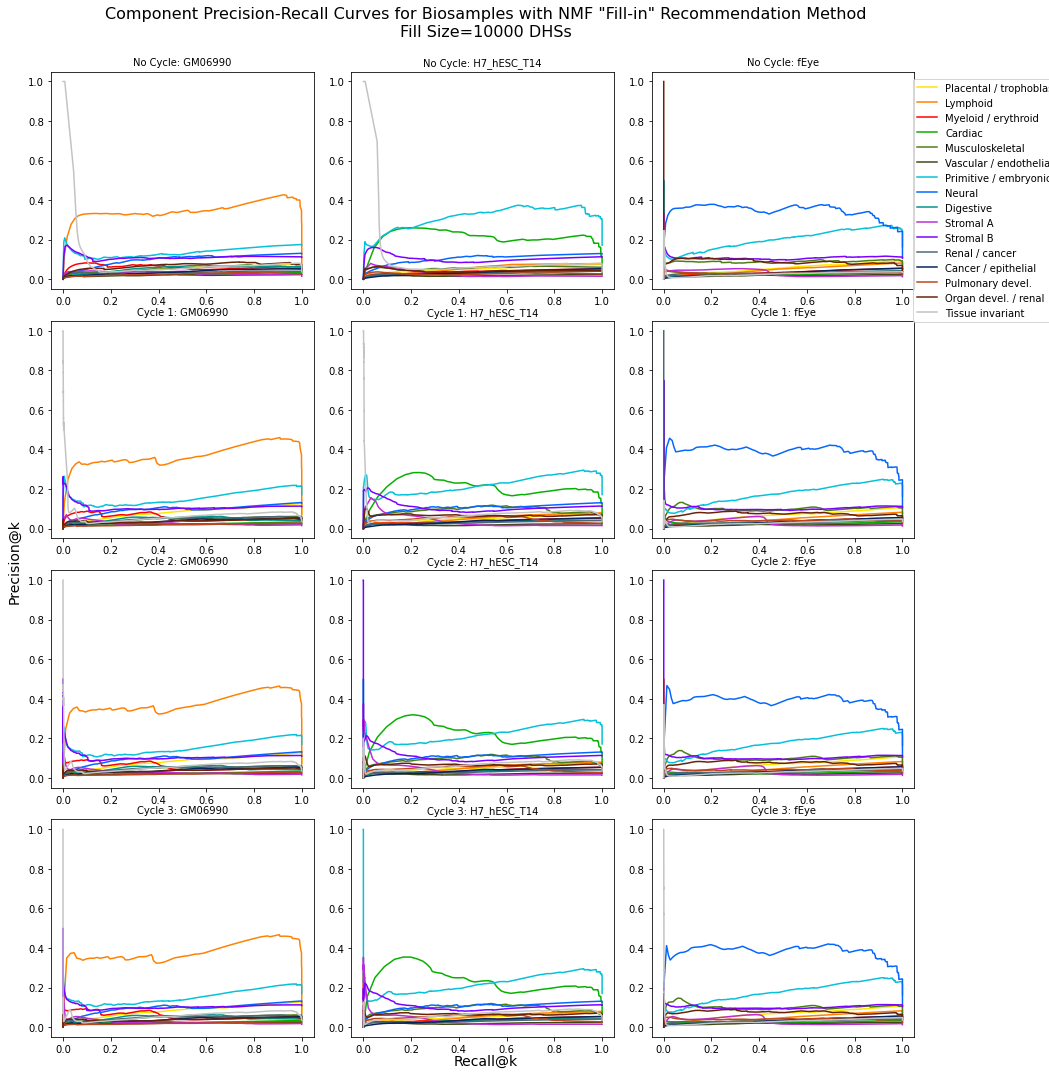

In [34]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes[:3], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_0_comp_recall[ind][i], cycle_0_comp_precision[ind][i], color=color[i])
    ax.set_title('No Cycle: ' + biosample_names[ind], fontsize=10)

for ax, ind in zip(fig.axes[3:6], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_1_comp_recall[ind][i], cycle_1_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 1: ' + biosample_names[ind], fontsize=10)
    
for ax, ind in zip(fig.axes[6:9], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_2_comp_recall[ind][i], cycle_2_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 2: ' + biosample_names[ind], fontsize=10)
    
for ax, ind in zip(fig.axes[9:12], range(3)):
    for i in range(len(comps)):
        ax.plot(cycle_3_comp_recall[ind][i], cycle_3_comp_precision[ind][i], color=color[i])
    ax.set_title('Cycle 3: ' + biosample_names[ind], fontsize=10)


fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(comps, loc = (0.87, 0.7))
# print(lines)
fig.suptitle('Component Precision-Recall Curves for Biosamples with NMF "Fill-in" Recommendation Method\nFill Size=10000 DHSs', fontsize=16, x=0.465, y=1.05)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Recall@k', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Precision@k', va='center', rotation='vertical', fontsize=14)

In [35]:
#finding AUC values for each component of each cycle 1 biosample
cycle_0_total_auc = []
for i in range(len(cycle_0_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_0_comp_precision[i])):
        comp_auc.append(auc(cycle_0_comp_recall[i][j], cycle_0_comp_precision[i][j]))
    cycle_0_total_auc.append(comp_auc)

In [36]:
#finding AUC values for each component of each cycle 1 biosample
cycle_1_total_auc = []
for i in range(len(cycle_1_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_1_comp_precision[i])):
        comp_auc.append(auc(cycle_1_comp_recall[i][j], cycle_1_comp_precision[i][j]))
    cycle_1_total_auc.append(comp_auc)

In [37]:
#finding AUC values for each component of each cycle 2 biosample
cycle_2_total_auc = []
for i in range(len(cycle_2_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_2_comp_precision[i])):
        comp_auc.append(auc(cycle_2_comp_recall[i][j], cycle_2_comp_precision[i][j]))
    cycle_2_total_auc.append(comp_auc)

In [38]:
#finding AUC values for each component of each cycle 3 biosample
cycle_3_total_auc = []
for i in range(len(cycle_3_comp_precision)):
    comp_auc = []
    for j in range(len(cycle_3_comp_precision[i])):
        comp_auc.append(auc(cycle_3_comp_recall[i][j], cycle_3_comp_precision[i][j]))
    cycle_3_total_auc.append(comp_auc)

Text(0.465, 1.05, 'Component PR Curve AUC Values for Biosamples with NMF "Fill-in" Recommendation Method\nFill Size=10000 DHSs')

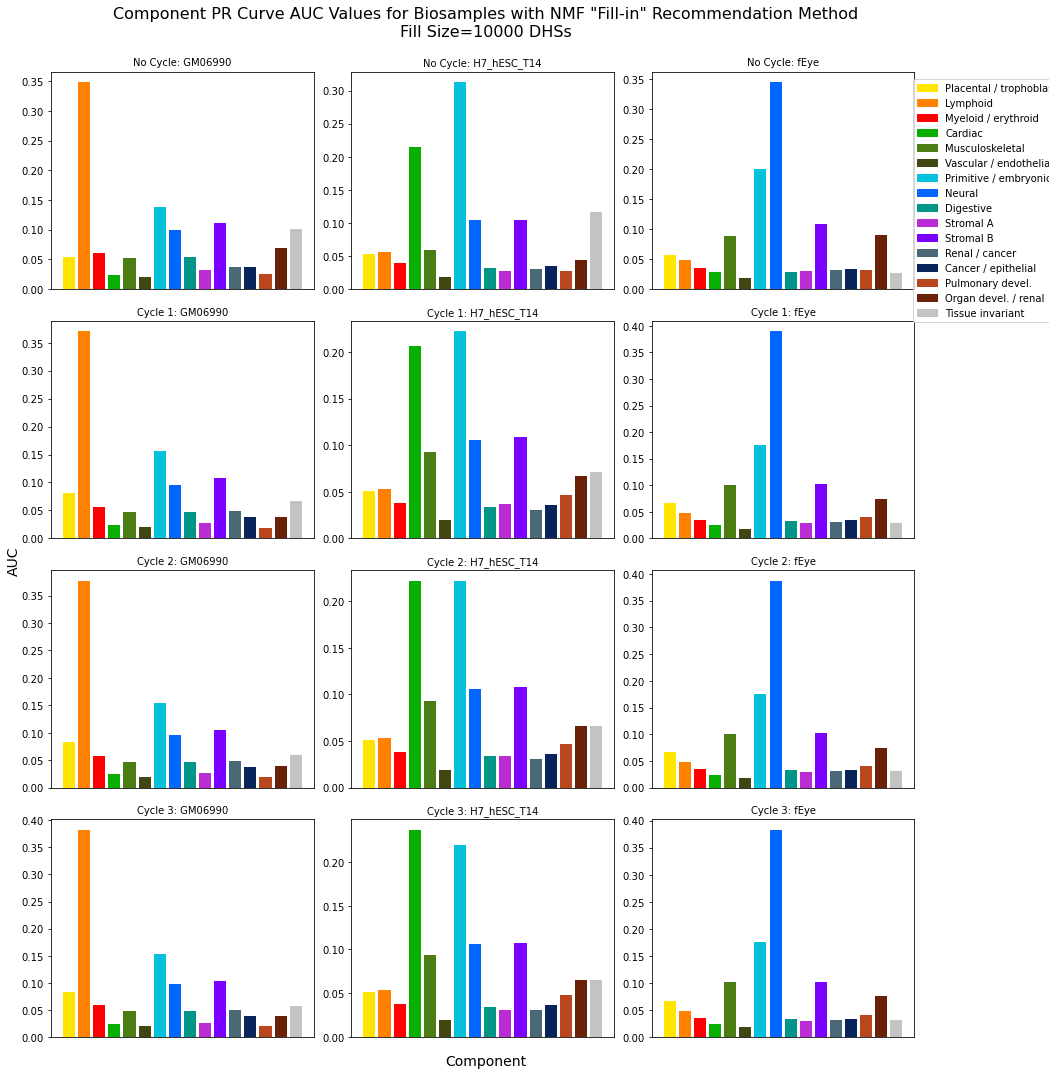

In [39]:
#plotting component PR curve AUC values
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14,14))
fig.tight_layout()
fig.patch.set_facecolor('white')

for ax, ind in zip(fig.axes[:3], range(3)):
    ax.bar(comps, cycle_0_total_auc[ind], color=color)
    ax.set_title('No Cycle: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])

for ax, ind in zip(fig.axes[3:6], range(3)):
    ax.bar(comps, cycle_1_total_auc[ind], color=color)
    ax.set_title('Cycle 1: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
for ax, ind in zip(fig.axes[6:9], range(3)):
    ax.bar(comps, cycle_2_total_auc[ind], color=color)
    ax.set_title('Cycle 2: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
for ax, ind in zip(fig.axes[9:12], range(3)):
    ax.bar(comps, cycle_3_total_auc[ind], color=color)
    ax.set_title('Cycle 3: ' + biosample_names[ind], fontsize=10)
    ax.set_xticks([])
    
fig.subplots_adjust(right=0.89)
# lines, labels = fig.axes[-1].get_legend_handles_labels()

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, comps, loc = (0.87, 0.7))
# print(lines)
# fig.xlabel('Recall@k')
# fig.ylabel('Precision@k')
fig.text(0.465, 0, 'Component', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'AUC', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Component PR Curve AUC Values for Biosamples with NMF "Fill-in" Recommendation Method\nFill Size=10000 DHSs', fontsize=16, x=0.465, y=1.05)

**Fill in function**

In [12]:
#Takes in Biosample and DHS decompositions, the full dhs presence absence matrix, a cut size, and a number
#of cycles. Generates recommendations for each biosample and fills in dhs matrix with the value 1 for the first 
#"cut_size" recommendations. New NMF decompositions are generated for the new data. This repeats for each cycle.
#The new DHS array and the new decomposition results
def fill_in(Basis=decomp_Basis, Mixture=decomp_Mixture, dhs_arr=dhs_array, cut_size=1000, cycles=1):
    n_biosamples, n_biosample_e = Basis.shape
    n_DHS_e, n_DHSs = Mixture.shape
    for i in range(cycles):
        print('Starting Cycle %s / %s' %(i+1, cycles))
        #finding known positives for all biosamples
        full_kp = np.where(dhs_arr==1)
        #Generate scores for each interaction
        scores = np.dot(Basis, Mixture)
        #sorting scores for each biosample
        sorted_scores = np.argsort(-scores, axis=1)
        updated_dhs_array = np.copy(dhs_arr)
        #for each row, updating DHS entries based on top predicted scores (ie top cut_size DHS indices=1)
        for biosample in range(n_biosamples):
            filtered_sorted_scores = np.delete(sorted_scores[biosample], np.where(np.isin(sorted_scores[biosample], full_kp[1][full_kp[0]==biosample])))
            first_cut_dhss = filtered_sorted_scores[:cut_size]
            updated_dhs_array[biosample, first_cut_dhss] = 1
            
        #regenerate NMF decompositions
        print('difference check:', np.sum(np.sum(updated_dhs_array-dhs_arr, axis=1)))
        print('NMF Decomposition:')
        new_decomp_Basis, new_decomp_Mixture, n_iter = non_negative_factorization(updated_dhs_array, W=Basis, H=Mixture, n_components=16, init='custom', random_state=3, max_iter=400, verbose=1)
        dhs_arr = updated_dhs_array
        Basis = new_decomp_Basis
        Mixture = new_decomp_Mixture

#     new_dhs = pd.DataFrame(updated_dhs_array)
    return updated_dhs_array, new_decomp_Basis, new_decomp_Mixture

**Functions needed to generate recommendations**

In [24]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(biosamples, signal_data, print_num=3, biosample_e=decomp_Basis, DHS_e=decomp_Mixture, dhs_df=dhs, ROIurl=False, comps_to_filter_out=[]): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_biosample_e = biosample_e.shape
    n_DHS_e, n_DHSs = DHS_e.shape
    return_list = []
    metadata = DHS_metadata.reset_index()
    comp_ser = metadata['component']
    chrom_ser = metadata['seqname']
    start_ser = metadata['start']
    end_ser = metadata['end']
    numsamples_ser = metadata['numsamples']
    identifier_ser = metadata['identifier']
    
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        if isinstance(biosample_name, str):
            biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
            
        else:
            biosample = biosample_name
            if (biosample > 732) & (n_biosamples == 747): #Pancreatic Cancer data
                relative_num = biosample - 733
                biosample_name = pc_sample_names[relative_num]
            elif (biosample > 732) & (n_biosamples == 771): #Immune data
                relative_num = biosample - 733
                biosample_name = immune_sample_names[relative_num]
            else:
                biosample_name = list(biosample_df[biosample_df['library order']==biosample+1]['Biosample name'])[0]
            
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs_df.T[biosample])) if dhs_pos == 1]
        print(len(known_positives))
        
        #filter out known positives from what will be recommended
        not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
        
        nki_series = pd.Series(not_known_ind)
        
        #DHSs model predictions that relate to biosample
        filtered_scores = np.dot(biosample_e[biosample, :], DHS_e[:, np.array(not_known_ind)])
        

        #rank from most related to least
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
        top_filtered_scores = filtered_scores[filtered_top_DHSs]
        
        comp_rec = list(comp_ser[top_rec_DHSs])
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_rec = list(start_ser[top_rec_DHSs])
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        identifier_rec = list(identifier_ser[top_rec_DHSs])
        
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_biosample.append(list(top_rec_DHSs))
        return_biosample.append(list(top_filtered_scores))
        
        if comps_to_filter_out:
            return_biosample = filter_out_recs(return_biosample, comps_to_filter_out)
        
        return_list.append(return_biosample)
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        
        if ROIurl == True:
            #creating ROIurl link
            if comps_to_filter_out:
                link_path = make_roi_url(biosample_name, str(biosample) + '_filtered', return_biosample)
            else:
                link_path = make_roi_url(biosample_name, str(biosample) + '_cycle3', return_biosample)
            print(link_path)
        
        if print_num > 0:
            print('   Number of Known DHSs: %s' %(len(known_positives)))
            print()
            print('   Recommended DHS Locations: ') 
            print('   Location | Component | Number of Samples | Biosample Signal/Average Signal | Left +DHS Signal | Right +DHS Signal')
        
        
        
            dhs_ids = top_rec_DHSs.to_numpy()
            #dhs to the right of recommended dhs
            dhs_right = dhs_ids[:]+1
            #dhs to the left of recommended dhs
            dhs_left = dhs_ids[:]-1
        
            #removing dhss that are "neighbored" across chromosomes
            chrm_list = list(np.unique(list(DHS_metadata['seqname'])))
            rows_per_chrm = [0]
            for chrm in chrm_list:
                max_row = max(rows_per_chrm)
                rows, col = DHS_metadata[DHS_metadata['seqname']==chrm].shape
                rows_per_chrm.append(rows + max_row)
            rows_per_chrm = np.array(rows_per_chrm)
        
            dhs_right = np.delete(dhs_right, np.isin(dhs_right, rows_per_chrm))
            dhs_left = np.delete(dhs_left, np.isin(dhs_left, rows_per_chrm-1))
        
            #determining presence/absense of dhss to right and left of recommended dhs
            right = dhs_array[biosample, dhs_right] 
            left = dhs_array[biosample, dhs_left]
        
            #signal data
            sample_rec_dhs_signal, rec_dhs_signal, rec_identifier = signal_values(list(top_rec_DHSs), signal_data)
            sample_right_dhs_signal, right_dhs_signal, right_identifier = signal_values(list(dhs_right), signal_data)
            sample_left_dhs_signal, left_dhs_signal, left_identifier = signal_values(list(dhs_left), signal_data)

        
        
            for i in range(print_num):
                chrom = chrom_rec[i]
                start = start_rec[i]
                end = end_rec[i]
                component = comp_rec[i]
                num_samples = numsamples_rec[i]
                sample_rec_dhs_signal_i = round(list(sample_rec_dhs_signal)[i], 3)
                rec_dhs_signal_i = round(float(list(rec_dhs_signal)[i]), 3)
                dhs_id = list(top_rec_DHSs)[i]
                right_id = list(np.where(dhs_right == dhs_id+1))[0] #+1
                if list(right_id) and right[right_id]==1:
                    sample_right_dhs_signal_i = round(sample_right_dhs_signal[int(right_id[0])], 3)
                    right_dhs_signal_i = round(right_dhs_signal[int(right_id[0])], 3)
                    right_print = str(round(sample_right_dhs_signal_i, 3)) + '/' + str(round(right_dhs_signal_i, 3))
                else:
                    right_print = 'N/A'
            
                left_id = list(np.where(dhs_left == dhs_id-1))[0]
                if list(left_id) and left[left_id]==1:
                    sample_left_dhs_signal_i = round(sample_left_dhs_signal[int(left_id[0])], 3)
                    left_dhs_signal_i = round(left_dhs_signal[int(left_id[0])], 3)
                    left_print = str(round(sample_left_dhs_signal_i, 3)) + '/' + str(round(left_dhs_signal_i, 3))
                else:
                    left_print = 'N/A'
                
                
                print('      %s:%s-%s | %s | %s | %s/%s | %s | %s'
                      %(chrom, start, end, component, num_samples, sample_rec_dhs_signal_i, rec_dhs_signal_i,
                       left_print, right_print))

    return return_list

#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision_multiple_k(rec_info, target_comp, k_vals):
    comps = np.array(rec_info[0])
#     print(comps)
    comps_np = np.where(comps == target_comp, 1, 0)
#     print(comps_np)
    total_of_comp = np.sum(comps_np)
#     print(total_of_comp)
    count_list = []
    for k in k_vals:
        comp_k = comps_np[:k]
        count = np.sum(comp_k)
        count_list.append(count)
    counts = np.array(count_list)
    precision = counts/k_vals
    recall = counts/total_of_comp
    return precision, recall

#creates ROIurl links for recommended DHSs
def make_roi_url(biosample_name, biosample, rec_info):
    today = date.today()
    bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_' + str(biosample_name) + '_' + str(biosample) + '_recs_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(100):
        f.write(rec_info[1][i] + '\t' + str(rec_info[2][i]) + '\t' + str(rec_info[3][i]) + '\t' + rec_info[0][i] + '\n')
    f.close()
    link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_' + str(biosample_name) + '_' + str(biosample) + '_recs_CT' + today.strftime("%Y%m%d") + '.bed'
    return link_path

def filter_in_recs(rec_info, comps_to_filter_in):
    rec_comps = np.array(rec_info[0])
    filter_inds = []
    for comp in comps_to_filter_in:
        filter_inds.extend(list(np.where(rec_comps == comp))[0])
    leftover_ind = np.array(filter_inds)
    return_comps = list(rec_comps[leftover_ind])
    return_chrm = list(np.array(rec_info[1])[leftover_ind])
    return_start = list(np.array(rec_info[2])[leftover_ind])
    return_end = list(np.array(rec_info[3])[leftover_ind])
    return_num_samples = list(np.array(rec_info[4])[leftover_ind])
    return_top_rec_DHSs = list(np.array(rec_info[5])[leftover_ind])
    return_top_filtered_scores = list(np.array(rec_info[6])[leftover_ind])
    
    return [return_comps, return_chrm, return_start, return_end, return_num_samples, return_top_rec_DHSs, return_top_filtered_scores, list(leftover_ind)]
# filter_test = filter_in_recs(unseen_pc_rec_info[0], ['Tissue invariant'])

def filter_out_recs(rec_info, comps_to_filter_out):
    rec_comps = np.array(rec_info[0])
    filter_inds = []
    for comp in comps_to_filter_out:
        filter_inds.extend(list(np.where(rec_comps == comp))[0])
    filter_inds = set(filter_inds)
    leftover_ind = np.array(list(set(range(len(rec_comps))) - filter_inds))
    return_comps = list(rec_comps[leftover_ind])
    return_chrm = list(np.array(rec_info[1])[leftover_ind])
    return_start = list(np.array(rec_info[2])[leftover_ind])
    return_end = list(np.array(rec_info[3])[leftover_ind])
    return_num_samples = list(np.array(rec_info[4])[leftover_ind])
    return_top_rec_DHSs = list(np.array(rec_info[5])[leftover_ind])
    return_top_filtered_scores = list(np.array(rec_info[6])[leftover_ind])
    
    return [return_comps, return_chrm, return_start, return_end, return_num_samples, return_top_rec_DHSs, return_top_filtered_scores, list(leftover_ind)]
# filter_test = filter_recs(unseen_rec_info[0], ['Tissue invariant'])

#Takes in recommended DHS indices and the signal data from a single biosample. Returns the average biosample signal
#across each recommended DHS and the average signal of all biosamples at each recommended DHS. 
def signal_values(dhs, signal_data):
    identifier_series = pd.Series(signal_data['name'])
    identifier = identifier_series[dhs]
    #Average biosample signal across each recommended DHS
    mean_signal_sample_series = pd.Series(signal_data['mean'])
    mean_signal_sample = mean_signal_sample_series[dhs]
    #Average signal of all biosamples at each recommended DHS
    mean_signal_DHS_series = pd.Series(DHS_metadata['mean_signal'])
    mean_signal_DHS = mean_signal_DHS_series[dhs]
    return list(mean_signal_sample), list(mean_signal_DHS), list(identifier)